# 02 · Separación con HTDemucs

**Fase 0.** Correr `htdemucs_6s` (el modelo del pipeline) sobre rock real, escuchar los stems y **medir** la separación contra los stems verdaderos de MUSDB18.

Usa grabaciones reales que descarga `npm run local:real-audio` en `data/real/` (no se suben al repo):

- **MUSDB18, extractos de 7 s** ([Zenodo](https://zenodo.org/records/3270814), CC BY 4.0): 144 fragmentos reales de rock y pop **con sus stems verdaderos** (voz, batería, bajo, resto).
- **TRIOS** ([Zenodo](https://zenodo.org/records/6797837), CC BY-NC-SA 2.0 UK): cinco tríos (Brahms, Lussier, Mozart, Schubert y *Take Five*) grabados instrumento por instrumento, **con el MIDI alineado**.

No hay grabaciones abiertas de orquesta completa con la verdad nota por nota (URMP y Bach10 piden registro); TRIOS es lo más cercano: instrumentos de orquesta reales, en grupos de tres.

La primera ejecución descarga los pesos (55 MB). En CPU tarda unos segundos por cada extracto de 7 s.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, "..")  # repo root: src.*

import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

REAL = Path("../data/real")  # npm run local:real-audio
OUTPUTS = Path("../outputs")
SR = 22050

from src.pipeline import audio as audio_io, separation
from src.evaluation import metrics

MODEL = separation.MODEL
print("model:", MODEL, "· device:", separation.device())

model: htdemucs_6s · device: cpu


In [2]:
MUSDB = REAL / "musdb7" / "test"
SONGS = ["Louis Cressy Band - Good Time", "The Doppler Shift - Atrophy", "Hollow Ground - Ill Fate"]
SEP_DIR = OUTPUTS / "separation" / MODEL / "musdb"

def separate(song: str) -> dict:
    out = SEP_DIR / song
    if not (out / "other.wav").exists():
        mix, sr = audio_io.load(MUSDB / song / "mixture.wav")
        separation.separate(mix, sr, out)  # misma función que el worker
    return {p.stem: p for p in sorted(out.glob("*.wav"))}

stems = {song: separate(song) for song in SONGS}

In [3]:
def listen(path):
    y, _ = librosa.load(path, sr=SR, mono=True)
    display(Audio(y, rate=SR))

for song in SONGS:
    print(f"\n=== {song} ===\nmezcla")
    listen(MUSDB / song / "mixture.wav")
    for name, path in stems[song].items():
        print(name)
        listen(path)


=== Louis Cressy Band - Good Time ===
mezcla


bass


drums


guitar


other


...

drums


guitar


other


piano


vocals


## Mel de cada stem

Qué energía queda en cada stem y dónde hay sangrado (bleeding). Fila de arriba: el stem verdadero de MUSDB cuando existe.

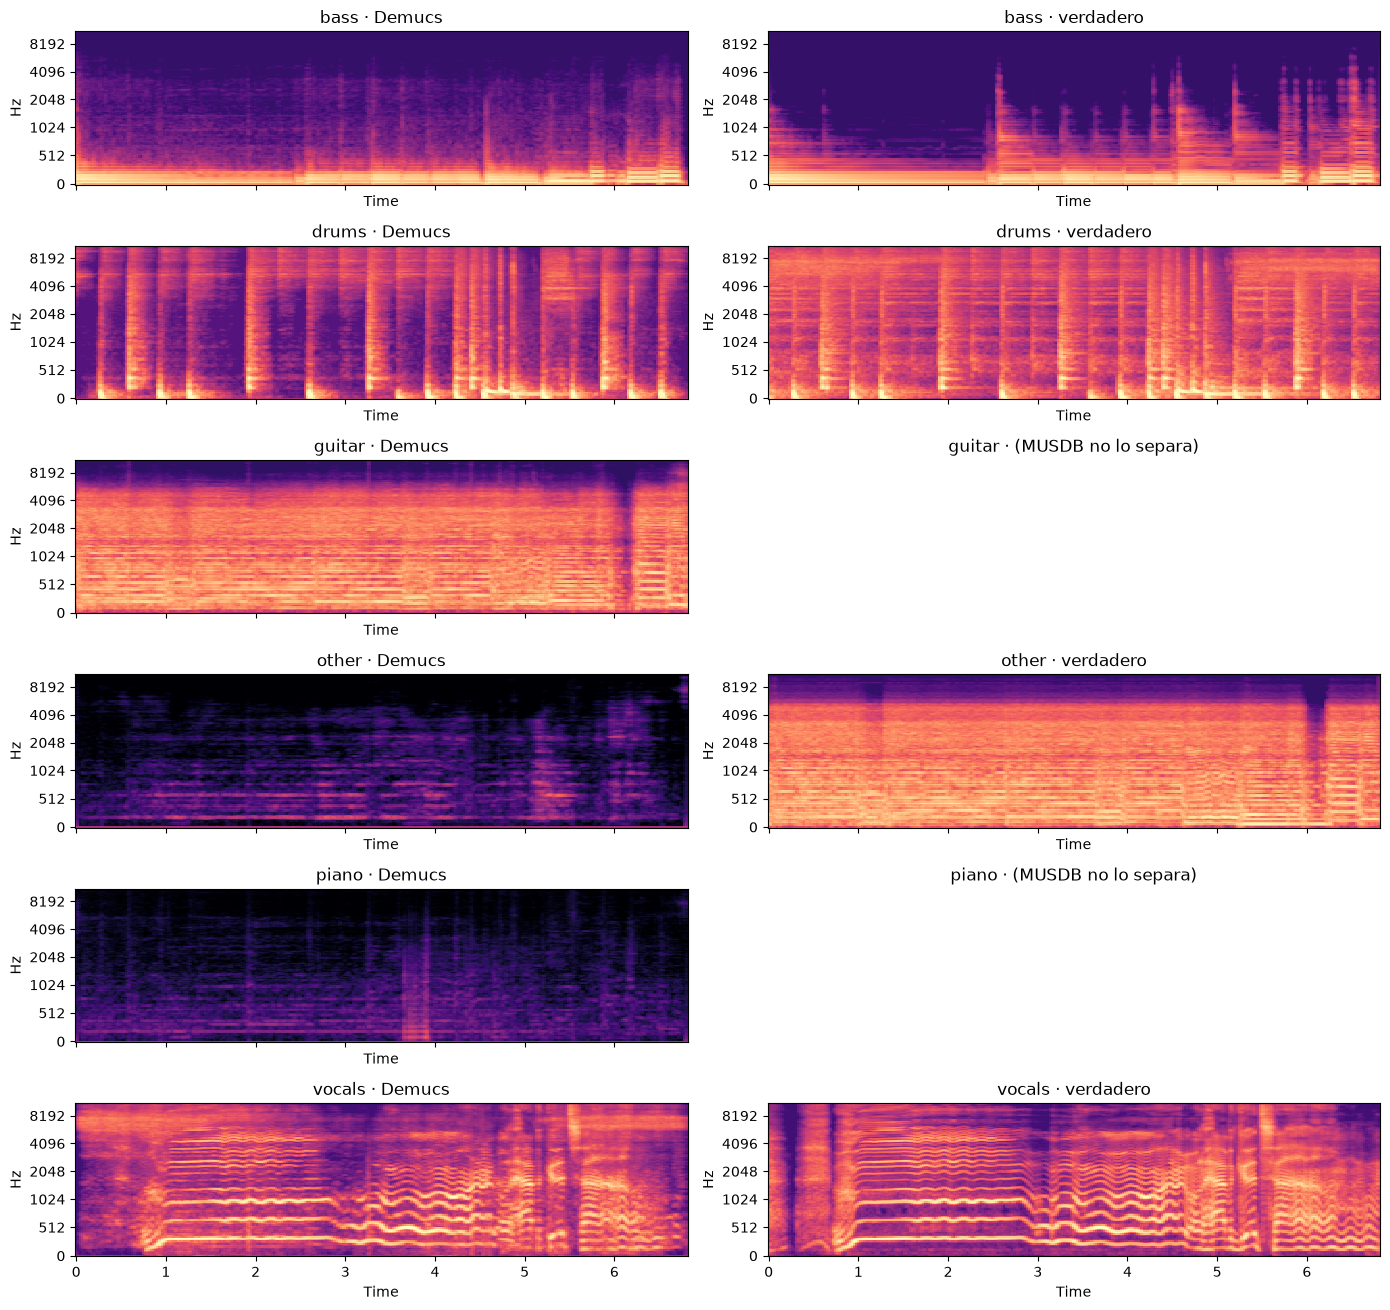

In [6]:
song = SONGS[0]
TRUE = {"drums": "drums", "bass": "bass", "vocals": "vocals", "other": "other"}
names = list(stems[song])

fig, axes = plt.subplots(len(names), 2, figsize=(14, 2.2 * len(names)), sharex=True)
for row, name in enumerate(names):
    for col, (label, path) in enumerate([("Demucs", stems[song][name]),
                                         ("verdadero", MUSDB / song / f"{TRUE.get(name, '')}.wav")]):
        ax = axes[row, col]
        if not path.is_file():
            ax.set_axis_off(); ax.set_title(f"{name} · (MUSDB no lo separa)"); continue
        y, _ = librosa.load(path, sr=SR, mono=True)
        M_db = librosa.power_to_db(librosa.feature.melspectrogram(y=y, sr=SR, n_mels=128) + 1e-10, ref=1.0)
        librosa.display.specshow(M_db, sr=SR, x_axis="time", y_axis="mel", ax=ax, vmin=-80, vmax=20, cmap="magma")
        ax.set_title(f"{name} · {label}")
plt.tight_layout()
plt.show()

## SDR contra los stems verdaderos (50 canciones de prueba)

SDR = $10\log_{10}\frac{\|s\|^2}{\|s-\hat s\|^2}$ en dB, por stem (`metrics.sdr`, la versión simple, no la de `museval`). MUSDB solo separa voz, batería, bajo y "resto", así que guitarra + piano + otros de Demucs se suman para compararlos con el "resto" verdadero. Como referencia, Demucs v4 reporta ≈ 9 dB de SDR medio en MUSDB18-HQ (canciones completas).

In [7]:
import csv

def load(path):
    y, _ = librosa.load(path, sr=44100, mono=False)
    return np.atleast_2d(y)

rows = []
for folder in sorted(MUSDB.iterdir()):
    est = separate(folder.name)
    estimate = {
        "vocals": load(est["vocals"]), "drums": load(est["drums"]), "bass": load(est["bass"]),
        "other": load(est["guitar"]) + load(est["piano"]) + load(est["other"]),
    }
    row = {"song": folder.name}
    for name, est_audio in estimate.items():
        ref = load(folder / f"{name}.wav")
        # Un stem verdadero en silencio (sin voz, p. ej.) no tiene SDR definido.
        row[name] = metrics.sdr(ref, est_audio) if np.abs(ref).max() > 1e-3 else np.nan
    # Qué parte del "resto" se fue a guitarra / piano.
    energy = {k: float(np.sum(load(est[k]) ** 2)) for k in ("guitar", "piano", "other")}
    total = sum(energy.values()) + 1e-12
    row.update({f"share_{k}": v / total for k, v in energy.items()})
    rows.append(row)

out = OUTPUTS / "separation" / "musdb7_test_sdr.csv"
with open(out, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0]))
    writer.writeheader(); writer.writerows(rows)

for name in ("vocals", "drums", "bass", "other"):
    values = np.array([r[name] for r in rows], dtype=float)
    print(f"{name:7s} SDR mediana={np.nanmedian(values):5.1f} dB  media={np.nanmean(values):5.1f}  "
          f"p10={np.nanpercentile(values, 10):5.1f}  p90={np.nanpercentile(values, 90):5.1f}  (n={np.sum(~np.isnan(values))})")
print("\nreparto del 'resto' estimado:", {k: f"{np.mean([r[f'share_{k}'] for r in rows]):.0%}" for k in ("guitar", "piano", "other")})
print("\nPeores 5 en bajo:")
for r in sorted(rows, key=lambda r: r["bass"])[:5]:
    print(f"  {r['bass']:5.1f} dB  {r['song']}")

vocals  SDR mediana=  8.6 dB  media=  8.6  p10=  4.3  p90= 12.4  (n=50)
drums   SDR mediana=  9.2 dB  media=  9.2  p10=  5.6  p90= 13.5  (n=50)
bass    SDR mediana=  8.2 dB  media=  7.6  p10=  1.3  p90= 14.1  (n=50)
other   SDR mediana=  4.7 dB  media=  4.4  p10=  0.5  p90=  7.3  (n=50)

reparto del 'resto' estimado: {'guitar': '66%', 'piano': '4%', 'other': '30%'}

Peores 5 en bajo:
   -3.3 dB  Signe Jakobsen - What Have You Done To Me
   -3.2 dB  Juliet's Rescue - Heartbeats
   -0.4 dB  Carlos Gonzalez - A Place For Us
    0.0 dB  PR - Oh No
    0.4 dB  Timboz - Pony


## Hallazgos

Ejecutado el 25 oct 2026 sobre los extractos de 7 s de MUSDB18 (rock y pop reales), con `htdemucs_6s` en CPU.

**SDR contra los stems verdaderos (50 canciones de prueba):**

| Stem  | Mediana | Media  | p10    | p90     |
| ----- | ------- | ------ | ------ | ------- |
| Voz   | 8,6 dB  | 8,6 dB | 4,3 dB | 12,4 dB |
| Batería | 9,2 dB | 9,2 dB | 5,6 dB | 13,5 dB |
| Bajo  | 8,2 dB  | 7,6 dB | 1,3 dB | 14,1 dB |
| Resto | 4,7 dB  | 4,4 dB | 0,5 dB | 7,3 dB  |

- **Calidad.** Voz, batería y bajo quedan en el rango que reporta Demucs v4 (≈ 9 dB en canciones completas; aquí es un SDR simple sobre extractos de 7 s, no `museval`). El "resto" es lo más difícil. El bajo es el más irregular: en 5 canciones baja de 0,5 dB (p. ej. *Signe Jakobsen*, −3,3 dB; *Juliet's Rescue*, −3,2 dB). Falta escucharlas para saber por qué.
- **¿Adónde va el "resto"?** 66 % a guitarra, 30 % a otros y solo 4 % a piano. En rock, el stem de guitarra carga casi todo; el de piano queda casi vacío, pero no en silencio: si el usuario pide piano en una canción sin piano, recibe sangrado. Sigue en pie la recomendación de descartar stems con poca energía.
- **Espectrogramas (*Good Time*):**
  - el stem de guitarra de Demucs se parece mucho al "resto" verdadero (es una canción de guitarras);
  - la voz sale limpia, con su vibrato, pero arrastra un poco de platillos en agudos antes de que entre el canto;
  - la batería de Demucs pierde parte del "colchón" de platillos que sí tiene la batería verdadera.
- **Calidad a oído:** sigue pendiente (requiere escuchar). Los audios de 3 canciones están arriba, mezcla y 6 stems cada una.
- **¿Probar `htdemucs_ft` o BS-RoFormer?** Para la voz sí: 8,6 dB de mediana deja margen, y los modelos RoFormer reportan mejor SDR en voz. Este notebook ya sirve de banco de pruebas: basta cambiar `A2S_DEMUCS_MODEL` y comparar la tabla. Para la ruta rock importa más el bajo, y ahí los casos malos (p10 1,3 dB) son el objetivo.